# 13 · Modern machine learning for causal inference

Heterogeneous treatment effects (CATE) with meta-learners, double machine learning (DML) and its IV version, uplift modelling, causal trees / forests, causal discovery, and finally a case study that **combines** predictive analytics with causal estimates.

**Method:** every technique is first *validated on a simulation with a known truth* (so you can see whether it works), then applied to the real tract data where that makes sense. Real-data treatment is again `tribal`, outcome `y_poi`; the usual observational caveats from notebooks 11 and 12 apply.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42
rng = np.random.default_rng(SEED)
f = pd.read_parquet(OUT / "model_frame.parquet")      # built in notebook 06
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
import networkx as nx, itertools
from sklearn.ensemble import HistGradientBoostingRegressor as HGBR, HistGradientBoostingClassifier as HGBC, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
gb = lambda: HGBR(max_depth=3, learning_rate=.06, max_iter=150, random_state=SEED)
gbc = lambda: HGBC(max_depth=3, learning_rate=.06, max_iter=150, random_state=SEED)
d = f.dropna(subset=["y_poi", "svi", "log_pop_density"]).reset_index(drop=True)
cov = ["rural", "log_pop_density", "svi", "cvi", "log_area_km2", "log_road_density"]
d[cov] = d[cov].fillna(d[cov].median())
Xr = pd.concat([d[cov], pd.get_dummies(d.region, drop_first=True, dtype=float)], axis=1)
Tr, Yr = d.tribal.values, d.y_poi.values
print(f"real data: n={len(d)}, treated={Tr.sum()}")

real data: n=9706, treated=872


## 1 · Heterogeneous effects: S-, T- and X-learners
**CATE** = effect for units with covariates x. First a simulation where the true CATE is known, scored by PEHE (RMSE of estimated vs true individual effect).

PEHE (lower is better), true ATE = 0.96
S-learner    0.985
T-learner    0.727
X-learner    0.488


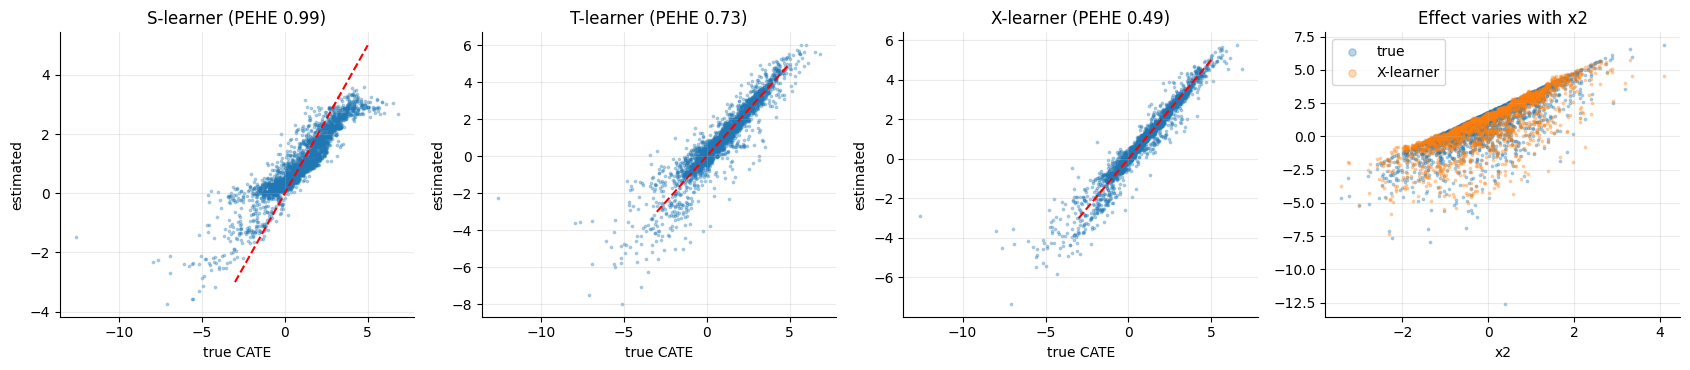

In [2]:
def make_sim(n, rng):
    X = rng.normal(size=(n, 5)); e = 1 / (1 + np.exp(-(0.8 * X[:, 0] - 0.4)))
    T = (rng.random(n) < e).astype(int); tau = 1 + 1.5 * X[:, 1] - (X[:, 2] ** 2 - 1) * .8
    mu0 = np.sin(X[:, 0]) + X[:, 1] * X[:, 2] + .5 * X[:, 3]
    Y = mu0 + tau * T + rng.normal(0, .7, n); return X, T, Y, tau, e
def s_learner(Xtr, Ttr, Ytr, Xte):
    m = gb().fit(np.c_[Xtr, Ttr], Ytr); return m.predict(np.c_[Xte, np.ones(len(Xte))]) - m.predict(np.c_[Xte, np.zeros(len(Xte))])
def t_learner(Xtr, Ttr, Ytr, Xte):
    m1, m0 = gb().fit(Xtr[Ttr == 1], Ytr[Ttr == 1]), gb().fit(Xtr[Ttr == 0], Ytr[Ttr == 0]); return m1.predict(Xte) - m0.predict(Xte)
def x_learner(Xtr, Ttr, Ytr, Xte):
    m1, m0 = gb().fit(Xtr[Ttr == 1], Ytr[Ttr == 1]), gb().fit(Xtr[Ttr == 0], Ytr[Ttr == 0])
    d1 = Ytr[Ttr == 1] - m0.predict(Xtr[Ttr == 1]); d0 = m1.predict(Xtr[Ttr == 0]) - Ytr[Ttr == 0]
    t1, t0 = gb().fit(Xtr[Ttr == 1], d1), gb().fit(Xtr[Ttr == 0], d0)
    g = gbc().fit(Xtr, Ttr).predict_proba(Xte)[:, 1]; return g * t0.predict(Xte) + (1 - g) * t1.predict(Xte)
X, T, Y, tau, e = make_sim(8000, rng); Xtr, Xte, Ttr, Tte, Ytr, Yte, tau_tr, tau_te = X[:5500], X[5500:], T[:5500], T[5500:], Y[:5500], Y[5500:], tau[:5500], tau[5500:]
est = {"S-learner": s_learner(Xtr, Ttr, Ytr, Xte), "T-learner": t_learner(Xtr, Ttr, Ytr, Xte), "X-learner": x_learner(Xtr, Ttr, Ytr, Xte)}
pehe = pd.Series({k: rmse(v, tau_te) for k, v in est.items()}); print("PEHE (lower is better), true ATE =", round(tau_te.mean(), 2)); print(pehe.round(3).to_string())
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a_, (k, v) in zip(ax, est.items()):
    a_.scatter(tau_te, v, s=3, alpha=.3); a_.plot([-3, 5], [-3, 5], "r--"); a_.set(xlabel="true CATE", ylabel="estimated", title=f"{k} (PEHE {pehe[k]:.2f})")
ax[3].scatter(Xte[:, 1], tau_te, s=3, alpha=.3, label="true"); ax[3].scatter(Xte[:, 1], est["X-learner"], s=3, alpha=.3, label="X-learner"); ax[3].legend(markerscale=3); ax[3].set_xlabel("x2"); ax[3].set_title("Effect varies with x2")
plt.tight_layout(); plt.show()

**Comment:** the S-learner tends to shrink the treatment effect toward zero (treatment is just one of many features for the tree model), while T- and X-learners separate the two response surfaces and recover the heterogeneity better. The X-learner helps most when treated and control groups are very different in size.

mean predicted effect among tribal tracts (ATT-like): {'S-learner': -0.001, 'T-learner': 0.016, 'X-learner': 0.032}


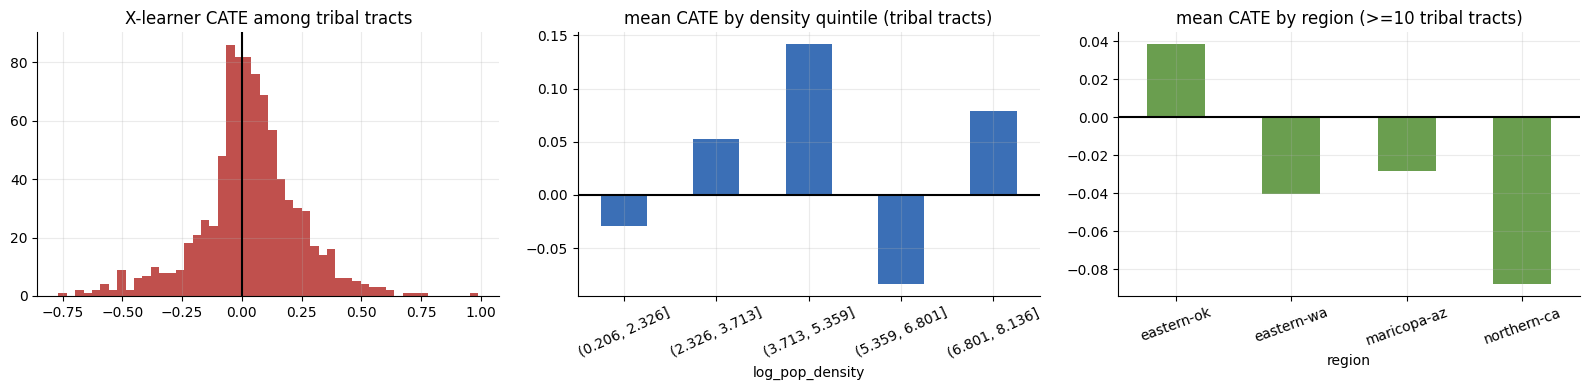

In [3]:
# Apply to the real data with out-of-fold predictions (each tract is scored by a model that never saw it)
Xv = Xr.values; cate = {k: np.zeros(len(Yr)) for k in ("S-learner", "T-learner", "X-learner")}
for tr_, te_ in KFold(5, shuffle=True, random_state=SEED).split(Xv):
    for k, fn in (("S-learner", s_learner), ("T-learner", t_learner), ("X-learner", x_learner)): cate[k][te_] = fn(Xv[tr_], Tr[tr_], Yr[tr_], Xv[te_])
cate = pd.DataFrame(cate); d["cate"] = cate["X-learner"]
print("mean predicted effect among tribal tracts (ATT-like):", cate[Tr == 1].mean().round(3).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(d.cate[Tr == 1], bins=50, color="#c0504d"); ax[0].axvline(0, color="k"); ax[0].set_title("X-learner CATE among tribal tracts")
(d[Tr == 1].groupby(pd.qcut(d.log_pop_density[Tr == 1], 5)).cate.mean()).plot.bar(ax=ax[1], color="#3b6fb6", rot=25); ax[1].axhline(0, color="k"); ax[1].set_title("mean CATE by density quintile (tribal tracts)")
d[Tr == 1].groupby("region").cate.agg(["mean", "size"]).query("size >= 10")["mean"].plot.bar(ax=ax[2], color="#6a9e4f", rot=20); ax[2].axhline(0, color="k"); ax[2].set_title("mean CATE by region (>=10 tribal tracts)")
plt.tight_layout(); plt.show()

**Comment:** the three learners put the average effect on tribal tracts at about 0 to +0.03 (S -0.001, T +0.016, X +0.032), so there is little average effect, while the individual predictions are widely spread. With only 872 treated tracts, 92% of them in one state, treat the heterogeneity patterns in the plots as hypotheses, not conclusions.

## 2 · Double machine learning (DML): Frisch-Waugh-Lovell with ML nuisance models
FWL: the coefficient of `T` in `Y ~ T + X` equals the coefficient from regressing the residual of `Y|X` on the residual of `T|X`. DML replaces the two linear regressions by flexible learners with **cross-fitting**, which handles non-linear confounding.

truth 1.00 | naive slope 2.44 | OLS with linear controls 2.43 | DML 1.12 (se 0.03)


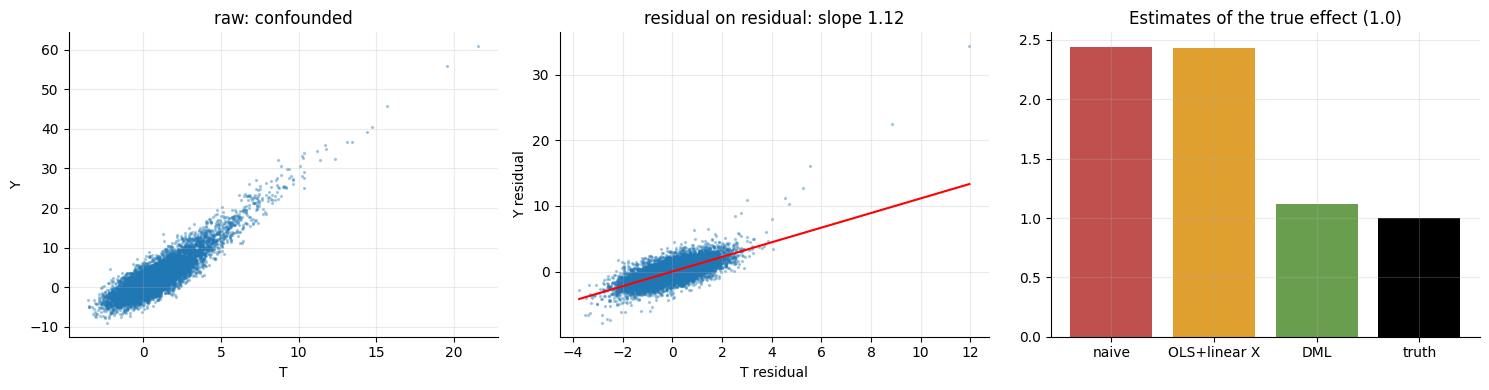

In [4]:
def dml(Y, T, X, k=5, seed=SEED, binary_T=True):
    rY, rT = np.zeros(len(Y)), np.zeros(len(Y))
    for tr_, te_ in KFold(k, shuffle=True, random_state=seed).split(X):
        rY[te_] = Y[te_] - gb().fit(X[tr_], Y[tr_]).predict(X[te_])
        rT[te_] = T[te_] - (gbc().fit(X[tr_], T[tr_]).predict_proba(X[te_])[:, 1] if binary_T else gb().fit(X[tr_], T[tr_]).predict(X[te_]))
    theta = (rT * rY).sum() / (rT ** 2).sum(); psi = (rY - theta * rT) * rT; se = np.sqrt(np.mean(psi ** 2) / len(Y)) / np.mean(rT ** 2)
    return theta, se, rY, rT
# simulation with NON-LINEAR confounding: OLS adjustment fails, DML works. True effect = 1.0
n = 8000; Xs_ = rng.normal(size=(n, 5)); g1 = np.sin(2 * Xs_[:, 0]) + Xs_[:, 1] ** 2; g2 = np.cos(Xs_[:, 0]) * Xs_[:, 2]
Ts_ = g1 + rng.normal(size=n); Ys_ = 1.0 * Ts_ + 2 * g1 - 1.5 * g2 + rng.normal(size=n)
ols_ = LinearRegression().fit(np.c_[Ts_, Xs_], Ys_).coef_[0]; th, se, rY_, rT_ = dml(Ys_, Ts_, Xs_, binary_T=False)
print(f"truth 1.00 | naive slope {np.polyfit(Ts_, Ys_, 1)[0]:.2f} | OLS with linear controls {ols_:.2f} | DML {th:.2f} (se {se:.2f})")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(Ts_, Ys_, s=2, alpha=.3); ax[0].set_title("raw: confounded"); ax[0].set(xlabel="T", ylabel="Y")
ax[1].scatter(rT_, rY_, s=2, alpha=.3); ax[1].plot(np.sort(rT_), th * np.sort(rT_), "r"); ax[1].set_title(f"residual on residual: slope {th:.2f}"); ax[1].set(xlabel="T residual", ylabel="Y residual")
ax[2].bar(["naive", "OLS+linear X", "DML", "truth"], [np.polyfit(Ts_, Ys_, 1)[0], ols_, th, 1.0], color=["#c0504d", "#e0a030", "#6a9e4f", "k"]); ax[2].set_title("Estimates of the true effect (1.0)")
plt.tight_layout(); plt.show()

DML (partially linear model): +0.032  (se 0.049, 95% CI [-0.065, +0.129])
OLS with the same controls  : +0.131  (se 0.045)   |   DML over 3 random splits: [0.023 0.034 0.023]


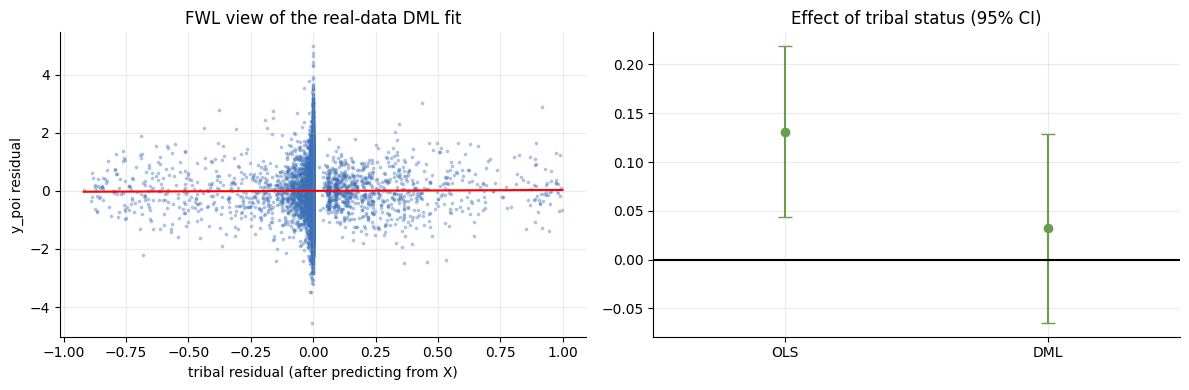

In [5]:
# Real data: effect of tribal status on y_poi
th, se, rY, rT = dml(Yr, Tr.astype(float), Xv)
lin = smf.ols("Y ~ T + " + " + ".join(cov) + " + C(region)", d.assign(Y=Yr, T=Tr)).fit(cov_type="HC3")
thetas = [dml(Yr, Tr.astype(float), Xv, seed=s)[0] for s in range(3)]
print(f"DML (partially linear model): {th:+.3f}  (se {se:.3f}, 95% CI [{th - 1.96 * se:+.3f}, {th + 1.96 * se:+.3f}])")
print(f"OLS with the same controls  : {lin.params['T']:+.3f}  (se {lin.bse['T']:.3f})   |   DML over 3 random splits: {np.round(thetas, 3)}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(rT, rY, s=3, alpha=.3, color="#3b6fb6"); ax[0].plot(np.sort(rT), th * np.sort(rT), "r"); ax[0].set(xlabel="tribal residual (after predicting from X)", ylabel="y_poi residual", title="FWL view of the real-data DML fit")
ax[1].errorbar([0, 1], [lin.params["T"], th], yerr=[1.96 * lin.bse["T"], 1.96 * se], fmt="o", capsize=5, color="#6a9e4f"); ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["OLS", "DML"]); ax[1].axhline(0, color="k"); ax[1].set_title("Effect of tribal status (95% CI)"); ax[1].set_xlim(-.5, 1.5)
plt.tight_layout(); plt.show()

**Comment:** in the simulation the naive slope (2.44) and the linear-control OLS (2.43) are both far from the true 1.0, while DML gets 1.12 (se 0.03): much closer, not exact (residual bias from imperfect nuisance fits). On the real data DML gives +0.03 (95% CI -0.07 to +0.13), stable across three random splits (0.02 to 0.03). That is lower than the OLS (+0.13) and the doubly-robust estimates of notebook 12 (+0.09 to +0.10), so the real-data effect is small and its size depends on how flexibly confounding is modelled; its sign and significance are not robust.

## 3 · DML for instrumental variables (partially linear IV)
When an *unobserved* confounder remains, an instrument Z (affects T, affects Y only through T) can still identify the effect. Our tract data has no credible instrument, so this is a **simulation**.

truth 2.00 | OLS (confounded by U) 2.68 | 2SLS 1.96 | DML-IV 1.96 (se 0.04)


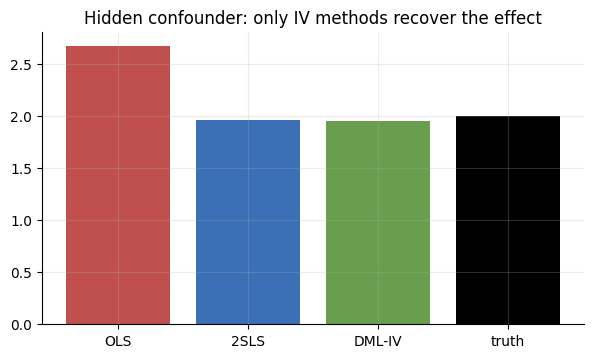

In [6]:
n = 10000; Xi = rng.normal(size=(n, 4)); U = rng.normal(size=n)                    # U: unobserved confounder
Z = (rng.random(n) < .5).astype(float) * 1.0 + .3 * Xi[:, 0]                          # instrument: independent of U
Ti = .9 * Z + 1.2 * U + .5 * Xi[:, 1] + rng.normal(size=n)
Yi = 2.0 * Ti + 1.5 * U + Xi[:, 0] + .5 * Xi[:, 2] + rng.normal(size=n)               # true effect 2.0
def pliv(Y, T, Z, X, k=5):
    r = {n_: np.zeros(len(Y)) for n_ in "YTZ"}
    for tr_, te_ in KFold(k, shuffle=True, random_state=SEED).split(X):
        for n_, v in (("Y", Y), ("T", T), ("Z", Z)): r[n_][te_] = v[te_] - gb().fit(X[tr_], v[tr_]).predict(X[te_])
    th = (r["Z"] * r["Y"]).sum() / (r["Z"] * r["T"]).sum(); psi = r["Z"] * (r["Y"] - th * r["T"]); return th, np.sqrt(np.mean(psi ** 2) / len(Y)) / abs(np.mean(r["Z"] * r["T"]))
ols_i = LinearRegression().fit(np.c_[Ti, Xi], Yi).coef_[0]; th_iv, se_iv = pliv(Yi, Ti, Z, Xi)
d_ = pd.DataFrame(np.c_[Yi, Ti, Z, Xi], columns=["y", "t", "z", "x1", "x2", "x3", "x4"]); t_hat = smf.ols("t ~ z + x1 + x2 + x3 + x4", d_).fit().fittedvalues
tsls = smf.ols("y ~ t_hat + x1 + x2 + x3 + x4", d_.assign(t_hat=t_hat)).fit().params["t_hat"]
print(f"truth 2.00 | OLS (confounded by U) {ols_i:.2f} | 2SLS {tsls:.2f} | DML-IV {th_iv:.2f} (se {se_iv:.2f})")
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.bar(["OLS", "2SLS", "DML-IV", "truth"], [ols_i, tsls, th_iv, 2.0], color=["#c0504d", "#3b6fb6", "#6a9e4f", "k"]); ax.set_title("Hidden confounder: only IV methods recover the effect"); plt.show()

**Comment:** OLS is biased upward by the hidden confounder; both 2SLS and DML-IV recover 2.0. DML-IV additionally lets the controls enter non-linearly. The price of IV is the *exclusion restriction*, which can never be tested from data alone.

## 4 · Uplift modelling (marketing outcome impact, MOI)

Uplift = the *incremental* effect of an intervention on each individual, so we target only the **persuadables**, not people who would convert anyway. Transferred to our setting: "which tracts would benefit most from a mapping drive?" We have no randomised campaign, so we simulate one with the four classic segments.

AUUC  uplift model 256.2 | response model 239.7 | random 97.9
incremental conversions: treat everyone 207 | top 30% by uplift 322 | top 30% at random 51


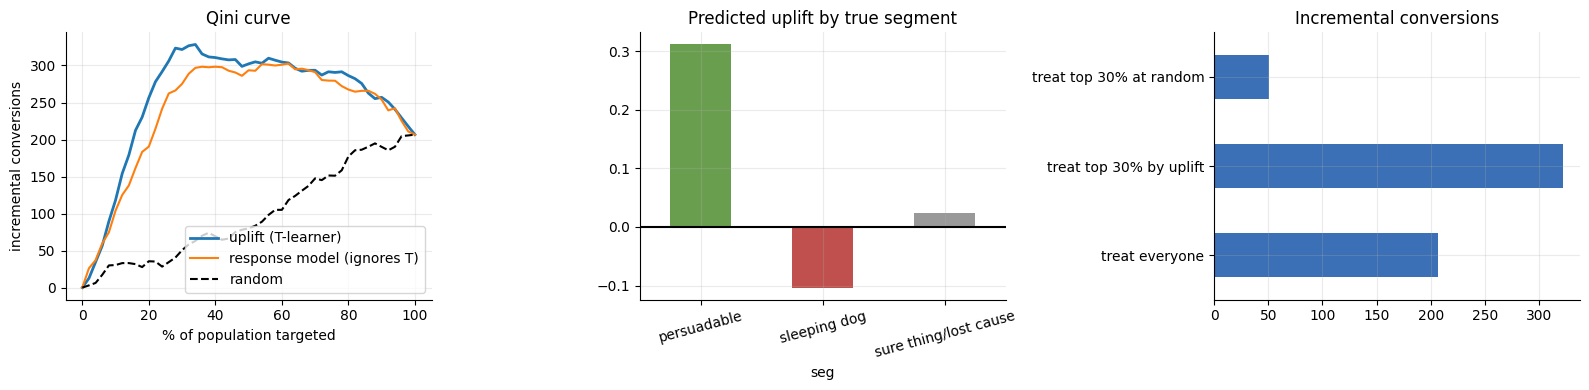

In [7]:
n = 20000; Xu = rng.normal(size=(n, 4)); Tu = rng.integers(0, 2, n)                    # randomised campaign
seg = np.select([Xu[:, 0] > .6, Xu[:, 0] < -.9], ["persuadable", "sleeping dog"], "sure thing/lost cause")
lift = np.select([seg == "persuadable", seg == "sleeping dog"], [.30, -.12], 0.0)
base = 1 / (1 + np.exp(-(.5 * Xu[:, 1] - .6)))                                          # converts anyway with this probability
Yu = (rng.random(n) < np.clip(base + lift * Tu, 0, 1)).astype(int)
tr_, te_ = np.arange(n) < 12000, np.arange(n) >= 12000
up = t_learner(Xu[tr_], Tu[tr_], Yu[tr_], Xu[te_])
def qini(score, T, Y, nb=50):
    order = np.argsort(-score); T, Y = T[order], Y[order]; out = [0.0]
    for k in np.linspace(len(Y) / nb, len(Y), nb).astype(int):
        t_, y_ = T[:k], Y[:k]; nt, nc = t_.sum(), (1 - t_).sum()
        out.append((y_[t_ == 1].sum() - y_[t_ == 0].sum() * nt / max(nc, 1)))
    return np.array(out)
q_up = qini(up, Tu[te_], Yu[te_]); q_rand = qini(rng.random(te_.sum()), Tu[te_], Yu[te_]); q_resp = qini(HGBR(max_depth=3).fit(Xu[tr_][Tu[tr_] == 1], Yu[tr_][Tu[tr_] == 1]).predict(Xu[te_]), Tu[te_], Yu[te_])   # predicts P(convert | treated), ignores uplift
x_ = np.linspace(0, 100, len(q_up)); auuc = lambda q: np.trapezoid(q, x_) / 100
print(f"AUUC  uplift model {auuc(q_up):.1f} | response model {auuc(q_resp):.1f} | random {auuc(q_rand):.1f}")
print(f"incremental conversions: treat everyone {q_up[-1]:.0f} | top 30% by uplift {q_up[int(.3 * (len(q_up) - 1))]:.0f} | top 30% at random {q_rand[int(.3 * (len(q_rand) - 1))]:.0f}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(x_, q_up, label="uplift (T-learner)", lw=2); ax[0].plot(x_, q_resp, label="response model (ignores T)"); ax[0].plot(x_, q_rand, "k--", label="random"); ax[0].legend(); ax[0].set(xlabel="% of population targeted", ylabel="incremental conversions", title="Qini curve")
df_u = pd.DataFrame({"seg": seg[te_], "uplift": up}); df_u.groupby("seg").uplift.mean().plot.bar(ax=ax[1], color=["#6a9e4f", "#c0504d", "#999"], rot=15); ax[1].axhline(0, color="k"); ax[1].set_title("Predicted uplift by true segment")
pd.Series({"treat everyone": q_up[-1], "treat top 30% by uplift": q_up[int(.3 * (len(q_up) - 1))], "treat top 30% at random": q_rand[int(.3 * (len(q_rand) - 1))]}).plot.barh(ax=ax[2], color="#3b6fb6"); ax[2].set_title("Incremental conversions")
plt.tight_layout(); plt.show()

**Comment:** targeting by predicted uplift beats random targeting (AUUC 256 vs 98) and a plain response model (240). Treating only the top 30% by uplift yields about 322 incremental conversions versus 207 for treating everyone and 51 for a random 30%, because sleeping dogs (negative effect) are skipped. The same logic would let an outreach programme concentrate mapping effort where the estimated gain is highest.

## 5 · Causal trees and causal-forest-style estimation
A **causal tree** splits the data to maximise differences in *treatment effect*, not in outcome. We use the transformed outcome `Y* = Y (T - e) / (e (1 - e))`, whose conditional mean equals the CATE, and **honest estimation**: the tree structure comes from one half of the data and leaf effects from the other.

      effect     se     n  n_treated
leaf                                
1     -0.501  0.078   374          1
4      0.098  0.091  1520        445
5     -0.187  0.019  2178          0
7      0.020  0.056   346          6
8      0.277  0.053   435          4


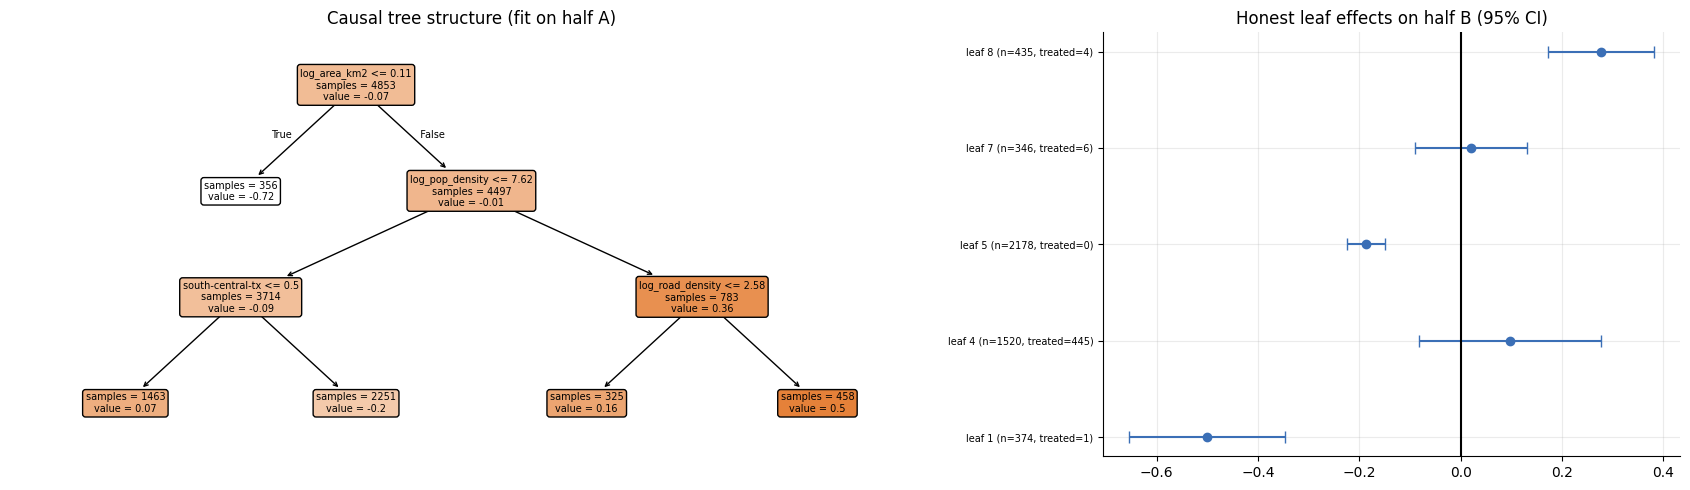

In [8]:
ps = np.clip(LogisticRegression(max_iter=2000).fit((Xv - Xv.mean(0)) / Xv.std(0), Tr).predict_proba((Xv - Xv.mean(0)) / Xv.std(0))[:, 1], .02, .98)
# doubly-robust pseudo-outcome (more stable than the plain transformed outcome)
m1, m0 = np.zeros(len(Yr)), np.zeros(len(Yr))
for tr_, te_ in KFold(5, shuffle=True, random_state=SEED).split(Xv):
    m1[te_] = gb().fit(Xv[tr_][Tr[tr_] == 1], Yr[tr_][Tr[tr_] == 1]).predict(Xv[te_]); m0[te_] = gb().fit(Xv[tr_][Tr[tr_] == 0], Yr[tr_][Tr[tr_] == 0]).predict(Xv[te_])
phi = m1 - m0 + Tr * (Yr - m1) / ps - (1 - Tr) * (Yr - m0) / (1 - ps)
idx = rng.permutation(len(Yr)); A, B = idx[: len(idx) // 2], idx[len(idx) // 2:]
tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=300, random_state=SEED).fit(Xv[A], phi[A])
leaf_B = tree.apply(Xv[B]); lt = pd.DataFrame({"leaf": leaf_B, "phi": phi[B], "T": Tr[B]}).groupby("leaf").agg(effect=("phi", "mean"), se=("phi", lambda s: s.std() / np.sqrt(len(s))), n=("phi", "size"), n_treated=("T", "sum"))
print(lt.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.6, 1]})
plot_tree(tree, feature_names=list(Xr.columns), filled=True, rounded=True, fontsize=7, ax=ax[0], impurity=False, precision=2); ax[0].set_title("Causal tree structure (fit on half A)")
ax[1].errorbar(lt.effect, range(len(lt)), xerr=1.96 * lt.se, fmt="o", capsize=4, color="#3b6fb6"); ax[1].axvline(0, color="k"); ax[1].set_yticks(range(len(lt))); ax[1].set_yticklabels([f"leaf {i} (n={n}, treated={t})" for i, n, t in zip(lt.index, lt.n, lt.n_treated)], fontsize=7)
ax[1].set_title("Honest leaf effects on half B (95% CI)"); plt.tight_layout(); plt.show()

**Comment:** the splits are mostly by region and tract size. Only leaf 4 holds a meaningful number of treated tracts (445): effect about +0.10 with 95% CI roughly -0.08 to +0.28, not distinguishable from zero. The other leaves contain 0 to 6 treated tracts, so their numbers come almost entirely from the outcome model (not from treated-vs-control contrasts) and must not be read as subgroup effects. Honest estimation (structure on one half, effects on the other) avoids inflated leaf effects, but cannot create overlap that the data lack.

PEHE on simulation: DR-forest 0.498 vs X-learner 0.488, T-learner 0.727


corr(forest, X-learner) on real data = 0.38


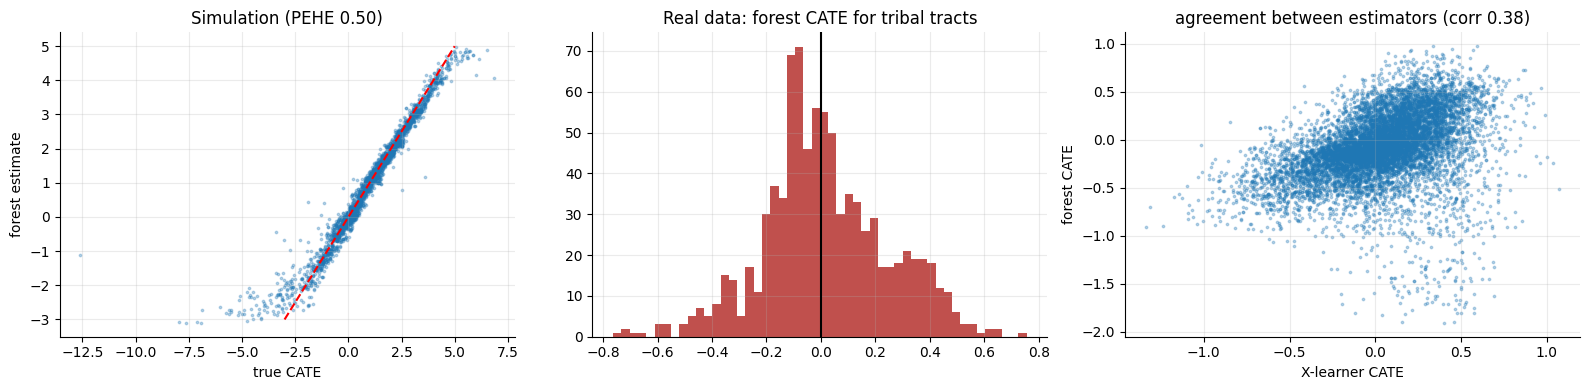

In [9]:
# Causal-forest-style estimator: a random forest on the doubly-robust pseudo-outcome, validated on the simulation first
def dr_forest(Xtr, Ttr, Ytr, Xte, k=5):
    e = np.clip(gbc().fit(Xtr, Ttr).predict_proba(Xtr)[:, 1], .03, .97); a1, a0 = np.zeros(len(Ytr)), np.zeros(len(Ytr))
    for tr_, te_ in KFold(k, shuffle=True, random_state=SEED).split(Xtr):
        a1[te_] = gb().fit(Xtr[tr_][Ttr[tr_] == 1], Ytr[tr_][Ttr[tr_] == 1]).predict(Xtr[te_]); a0[te_] = gb().fit(Xtr[tr_][Ttr[tr_] == 0], Ytr[tr_][Ttr[tr_] == 0]).predict(Xtr[te_])
    ph = a1 - a0 + Ttr * (Ytr - a1) / e - (1 - Ttr) * (Ytr - a0) / (1 - e)
    return RandomForestRegressor(300, min_samples_leaf=40, max_features=.6, random_state=SEED, n_jobs=-1).fit(Xtr, ph).predict(Xte)
cf = dr_forest(Xtr, Ttr, Ytr, Xte); pehe_cf = rmse(cf, tau_te)
print(f"PEHE on simulation: DR-forest {pehe_cf:.3f} vs X-learner {pehe['X-learner']:.3f}, T-learner {pehe['T-learner']:.3f}")
cf_real = np.zeros(len(Yr))
for tr_, te_ in KFold(5, shuffle=True, random_state=SEED).split(Xv): cf_real[te_] = dr_forest(Xv[tr_], Tr[tr_], Yr[tr_], Xv[te_])
d["cf"] = cf_real; print(f"corr(forest, X-learner) on real data = {np.corrcoef(d.cate, d.cf)[0, 1]:.2f}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(tau_te, cf, s=3, alpha=.3); ax[0].plot([-3, 5], [-3, 5], "r--"); ax[0].set(xlabel="true CATE", ylabel="forest estimate", title=f"Simulation (PEHE {pehe_cf:.2f})")
ax[1].hist(d.cf[Tr == 1], bins=50, color="#c0504d"); ax[1].axvline(0, color="k"); ax[1].set_title("Real data: forest CATE for tribal tracts")
ax[2].scatter(d.cate, d.cf, s=3, alpha=.3); ax[2].set(xlabel="X-learner CATE", ylabel="forest CATE", title=f"agreement between estimators (corr {np.corrcoef(d.cate, d.cf)[0, 1]:.2f})")
plt.tight_layout(); plt.show()

**Comment:** a forest on doubly-robust pseudo-outcomes (the idea behind causal forests; note this is our own lightweight version, not the full `grf` algorithm) tracks the true simulated effects well (PEHE 0.50, close to the X-learner's 0.49). On the real data, however, its CATEs correlate only 0.38 with the X-learner's, so the two learners do not agree on *who* benefits: the heterogeneity signal in the real data is weak or poorly identified, which fits the small number of treated tracts.

## 6 · Automated discovery of causal structure: the PC algorithm
PC removes an edge when two variables become independent given some set (conditional-independence tests), then orients **colliders** using the separating sets. It recovers the graph only up to its *Markov equivalence class*.

In [10]:
from scipy.stats import norm
def pc_algorithm(D, names, alpha=1e-3):
    n, p = D.shape; C = np.corrcoef(D.T); adj = {i: set(range(p)) - {i} for i in range(p)}; sep = {}
    def indep(i, j, S):
        idx = [i, j] + list(S); P = np.linalg.pinv(C[np.ix_(idx, idx)]); r = -P[0, 1] / np.sqrt(P[0, 0] * P[1, 1]); r = np.clip(r, -.9999999, .9999999)
        z = .5 * np.log((1 + r) / (1 - r)) * np.sqrt(n - len(S) - 3); return 2 * (1 - norm.cdf(abs(z))) > alpha
    l = 0
    while any(len(adj[i]) - 1 >= l for i in adj):
        for i in range(p):
            for j in sorted(adj[i]):
                if j not in adj[i]: continue
                for S in itertools.combinations(sorted(adj[i] - {j}), l):
                    if indep(i, j, S): adj[i].discard(j); adj[j].discard(i); sep[frozenset((i, j))] = set(S); break
        l += 1
    directed = set()
    for k in range(p):
        for i, j in itertools.combinations(sorted(adj[k]), 2):
            if j not in adj[i] and k not in sep.get(frozenset((i, j)), set()): directed |= {(i, k), (j, k)}
    changed = True                                                      # Meek rule 1: a -> b - c with a,c non-adjacent  =>  b -> c
    while changed:
        changed = False
        for (a, b) in list(directed):
            for c in adj[b]:
                if c != a and c not in adj[a] and (b, c) not in directed and (c, b) not in directed: directed.add((b, c)); changed = True
    und = {(min(i, j), max(i, j)) for i in adj for j in adj[i] if (i, j) not in directed and (j, i) not in directed}
    return [(names[a], names[b]) for a, b in directed], [(names[a], names[b]) for a, b in und]
# simulation with a known DAG:  A -> B -> C,  A -> D <- C
nS = 6000; A = rng.normal(size=nS); B = .8 * A + rng.normal(size=nS); Cc = .8 * B + rng.normal(size=nS); Dd = .7 * A + .7 * Cc + rng.normal(size=nS)
dir_, und_ = pc_algorithm(np.c_[A, B, Cc, Dd], list("ABCD"))
print("true edges    : A->B, B->C, A->D, C->D\nPC directed   :", sorted(dir_), "\nPC undirected :", sorted(und_))

true edges    : A->B, B->C, A->D, C->D
PC directed   : [('A', 'D'), ('C', 'D')] 
PC undirected : [('A', 'B'), ('B', 'C')]


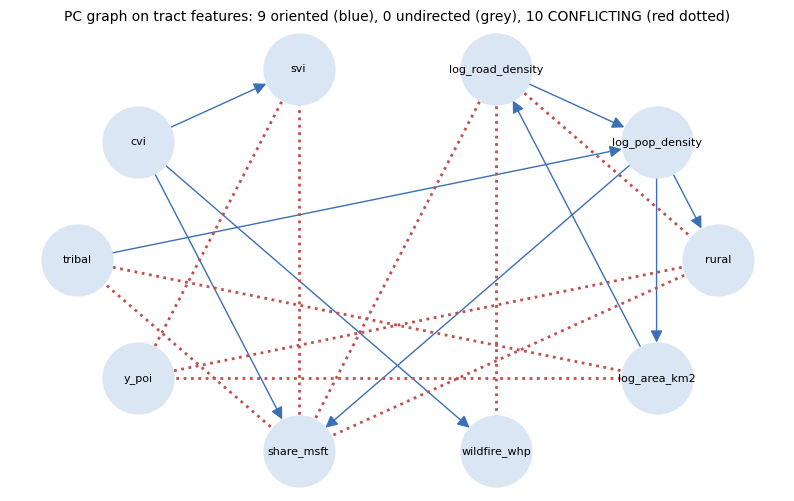

oriented: [('cvi', 'share_msft'), ('cvi', 'svi'), ('cvi', 'wildfire_whp'), ('log_area_km2', 'log_road_density'), ('log_pop_density', 'log_area_km2'), ('log_pop_density', 'rural'), ('log_pop_density', 'share_msft'), ('log_road_density', 'log_pop_density'), ('tribal', 'log_pop_density')]
undirected: []
conflicting (oriented both ways): [('log_area_km2', 'tribal'), ('log_area_km2', 'y_poi'), ('log_road_density', 'rural'), ('log_road_density', 'share_msft'), ('log_road_density', 'wildfire_whp'), ('rural', 'share_msft'), ('rural', 'y_poi'), ('share_msft', 'svi'), ('share_msft', 'tribal'), ('svi', 'y_poi')]


In [11]:
names = ["rural", "log_pop_density", "log_road_density", "svi", "cvi", "tribal", "y_poi", "share_msft", "wildfire_whp", "log_area_km2"]
Dm = d[names].copy(); Dm = Dm.fillna(Dm.median()); dir_r, und_r = pc_algorithm(Dm.values, names, alpha=1e-3)
conf = sorted({tuple(sorted(e)) for e in dir_r if (e[1], e[0]) in dir_r})                   # edges oriented both ways by different v-structures
dir_r = [e for e in dir_r if tuple(sorted(e)) not in conf]
G = nx.DiGraph(); G.add_nodes_from(names); G.add_edges_from(dir_r)
fig, ax = plt.subplots(figsize=(10, 6)); pos = nx.circular_layout(G)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#dbe6f5", node_size=2600); nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=dir_r, arrows=True, arrowsize=18, node_size=2600, edge_color="#3b6fb6")
nx.draw_networkx_edges(nx.Graph(und_r), pos, ax=ax, edgelist=und_r, node_size=2600, edge_color="#999", style="dashed")
nx.draw_networkx_edges(nx.Graph(conf), pos, ax=ax, edgelist=conf, node_size=2600, edge_color="#c0504d", style="dotted", width=2)
ax.set_title(f"PC graph on tract features: {len(dir_r)} oriented (blue), {len(und_r)} undirected (grey), {len(conf)} CONFLICTING (red dotted)", fontsize=10); ax.axis("off"); plt.show()
print("oriented:", sorted(dir_r)); print("undirected:", sorted(und_r)); print("conflicting (oriented both ways):", conf)

**Comment:** in the simulation PC recovers the skeleton and orients the collider A -> D <- C from the data alone (the chain A-B-C stays undirected because it is Markov-equivalent in the other direction). On the real variables the output is **not trustworthy**: many edges get contradictory orientations from different v-structures (red dotted), the usual symptom of violated assumptions (non-Gaussian and binary variables, hidden common causes, strongly collinear density / road / area variables). Use the adjacency (which variables are linked at all) as a hint at most, and settle directions with domain knowledge, as in the hand-built DAG of notebook 11.

## 7 · Case study: combining classical analytics with causal inference
A predictive model answers *'which tracts look under-mapped?'*; a causal model answers *'what would changing X do?'*. Comparing the two shows where they disagree.

predictive model hold-out R2 = 0.323
                  perm. importance (RMSE increase)  effect     se
rural                                        0.020  -0.399  0.037
log_pop_density                              0.335  -0.948  0.055
svi                                          0.120   0.314  0.016
cvi                                          0.051  -0.200  0.015
log_road_density                             0.297   0.325  0.038
log_area_km2                                 0.163  -0.634  0.048
tribal                                       0.000   0.032  0.049


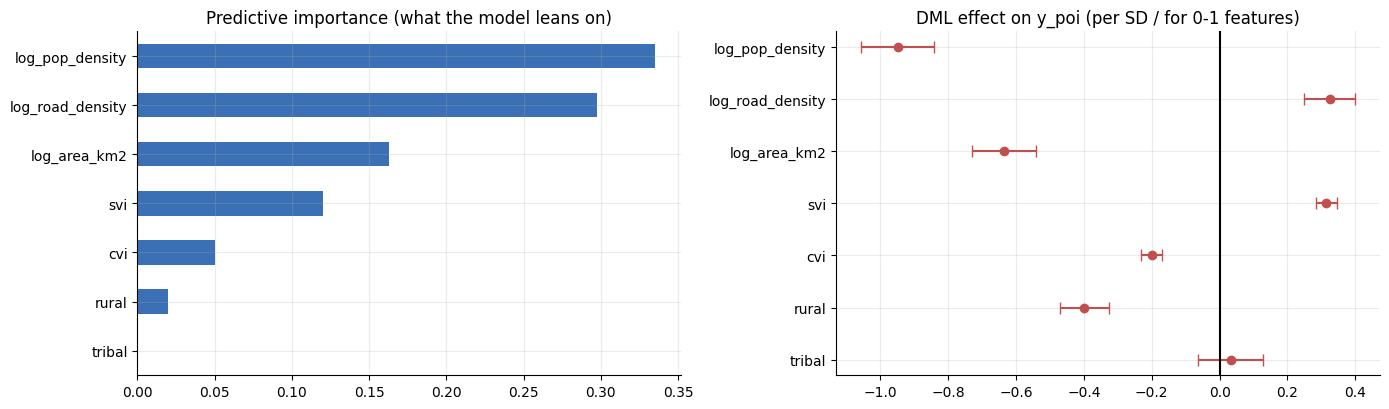

In [12]:
from sklearn.inspection import permutation_importance
feats = ["rural", "log_pop_density", "svi", "cvi", "log_road_density", "log_area_km2", "tribal"]
Xc = pd.concat([d[feats], pd.get_dummies(d.region, drop_first=True, dtype=float)], axis=1)
tr_i, te_i = next(KFold(4, shuffle=True, random_state=SEED).split(Xc))
gm = HGBR(max_depth=4, learning_rate=.05, max_iter=300, random_state=SEED).fit(Xc.iloc[tr_i], Yr[tr_i])
r2 = 1 - ((Yr[te_i] - gm.predict(Xc.iloc[te_i])) ** 2).sum() / ((Yr[te_i] - Yr[te_i].mean()) ** 2).sum()
pi = permutation_importance(gm, Xc.iloc[te_i], Yr[te_i], n_repeats=10, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, Xc.columns)[feats]
# causal (DML) effect of each feature on y_poi, controlling for all the others; effects are per 1 SD for continuous features
eff = {}
for fe in feats:
    others = [c for c in Xc.columns if c != fe]; t_ = Xc[fe].values.astype(float); sd = t_.std() if len(np.unique(t_)) > 2 else 1.0
    th, se, _, _ = dml(Yr, t_, Xc[others].values, binary_T=len(np.unique(t_)) == 2); eff[fe] = (th * sd, se * sd)
eff = pd.DataFrame(eff, index=["effect", "se"]).T
print(f"predictive model hold-out R2 = {r2:.3f}"); print(pd.concat([imp.rename("perm. importance (RMSE increase)"), eff], axis=1).round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
imp.sort_values().plot.barh(ax=ax[0], color="#3b6fb6"); ax[0].set_title("Predictive importance (what the model leans on)")
e2 = eff.loc[imp.sort_values().index]; ax[1].errorbar(e2.effect, range(len(e2)), xerr=1.96 * e2.se, fmt="o", capsize=4, color="#c0504d"); ax[1].axvline(0, color="k"); ax[1].set_yticks(range(len(e2))); ax[1].set_yticklabels(e2.index); ax[1].set_title("DML effect on y_poi (per SD / for 0-1 features)")
plt.tight_layout(); plt.show()

**Comment:** the predictive model (hold-out R2 0.32) leans on density (importance 0.34), road density (0.30), tract area (0.16) and SVI (0.12), while `tribal` has importance 0.00 and a DML effect of +0.03 (CI includes 0): both views say tribal status adds nothing once the others are known. For the strongly collinear variables the two views disagree: `rural` has tiny predictive importance (0.02) because density and roads already carry its information, yet a sizeable conditional DML effect (-0.40), and density's conditional effect (-0.95 per SD) has the opposite sign of its marginal correlation (+0.34, notebook 06). That is what collinearity looks like, so read these as *conditional associations*, not as independent levers that could be pulled one at a time.

**Caveats:** every causal estimate here assumes no unmeasured confounding and, for continuous features, a linear partially-linear effect; the outcome is a proxy (POIs per building), not the hidden coverage-gap score.